📥 Loading ALL Data (2018-2025)...

🚀 Running In-Sample (2018-2022): 2018-01-01 -> 2022-12-31...

🚀 Running Out-Sample (2023-2025): 2023-01-01 -> 2025-01-01...

METRIC          | IN-SAMPLE (18-22)  | OUT-SAMPLE (23-25)
-------------------------------------------------------
Total Return    |            87.54% |            42.79%
Max Drawdown    |            -7.65% |            -6.17%
Sharpe Ratio    |              1.18 |              1.75
Total Trades    |                56 |                99


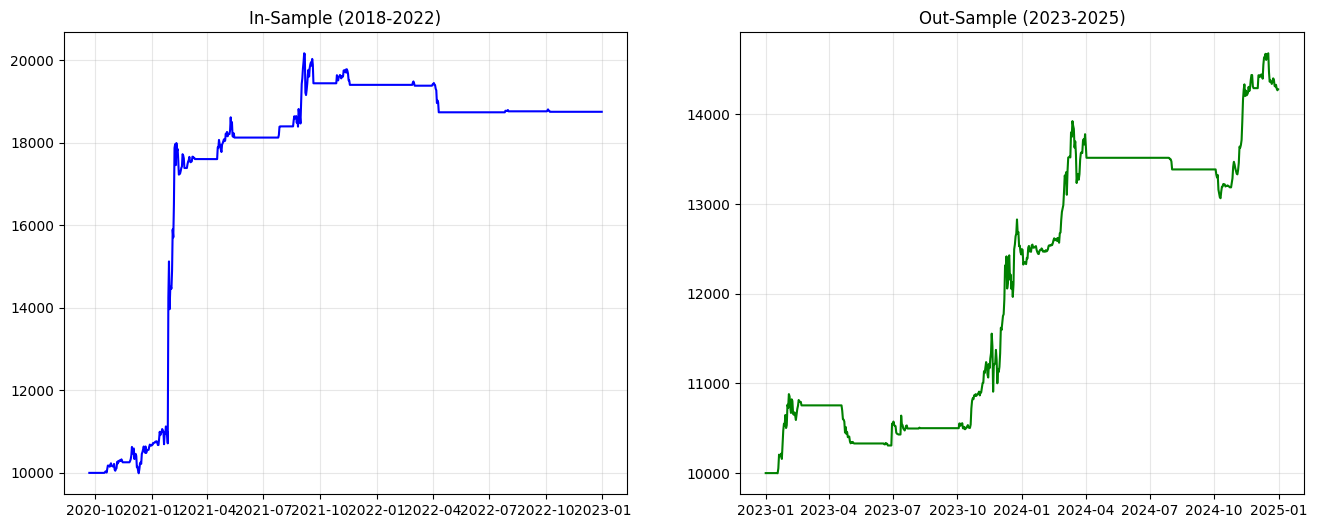

In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import uuid
from datetime import timedelta

# --- 1. CẤU HÌNH ---
ASSETS = [
    'BTC-USD', 'ETH-USD', 'BNB-USD', 'SOL-USD', 'ADA-USD',
    'XRP-USD', 'DOGE-USD', 'DOT-USD', 'LINK-USD', 'LTC-USD',
    'AVAX-USD', 'MATIC-USD'
]
BTC_SYMBOL = 'BTC-USD'

# THAM SỐ CHIẾN LƯỢC (RELAXED)
INITIAL_CAPITAL = 10000
ALLOCATION_PER_TRADE = 0.10
FEE = 0.001

DRIFT_WINDOW = 30
GREEN_DAYS_THRESHOLD = 18
VOL_SMA_FAST = 10
VOL_SMA_SLOW = 30

SAFE_BTC_EMA = 50
SAFE_BTC_DROP = -0.03

ENTRY_EMA = 20
ENTRY_RSI_PERIOD = 4
ENTRY_RSI_THRESH = 35

EXIT_RSI_OVERBOUGHT = 75
EXIT_TRAIL_EMA = 10
STOP_LOSS_FIXED = 0.07
EXIT_TREND_EMA = 50

# --- 2. DATA LOAD & PREP ---
def fetch_and_prep_data(symbol, start_date, end_date):
    try:
        # Load dư 100 ngày để tính chỉ báo đầu kỳ
        start_load = pd.to_datetime(start_date) - timedelta(days=100)
        df = yf.download(symbol, start=start_load, end=end_date, progress=False, auto_adjust=False)

        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)
        df.columns = df.columns.str.lower()
        df.index = df.index.tz_localize(None)

        # INDICATORS
        df['change'] = df['close'].pct_change()
        df['is_green'] = np.where(df['change'] > 0, 1, 0)
        df['green_days'] = df['is_green'].rolling(DRIFT_WINDOW).sum()

        df['vol_ma_fast'] = df['volume'].rolling(VOL_SMA_FAST).mean()
        df['vol_ma_slow'] = df['volume'].rolling(VOL_SMA_SLOW).mean()

        df['ema_10'] = df['close'].ewm(span=EXIT_TRAIL_EMA, adjust=False).mean()
        df['ema_20'] = df['close'].ewm(span=ENTRY_EMA, adjust=False).mean()
        df['ema_50'] = df['close'].ewm(span=EXIT_TREND_EMA, adjust=False).mean()

        delta = df['close'].diff()
        gain = (delta.where(delta > 0, 0)).ewm(alpha=1/ENTRY_RSI_PERIOD, adjust=False).mean()
        loss = (-delta.where(delta < 0, 0)).ewm(alpha=1/ENTRY_RSI_PERIOD, adjust=False).mean()
        rs = gain / loss
        df['rsi'] = 100 - (100 / (1 + rs))

        return df
    except:
        return pd.DataFrame()

# --- 3. CORE BACKTEST FUNCTION ---
def run_period_backtest(label, start_date, end_date, btc_full, market_data_full):
    print(f"\n🚀 Running {label}: {start_date} -> {end_date}...")

    # Filter Data theo Period
    start_ts = pd.to_datetime(start_date)
    end_ts = pd.to_datetime(end_date)

    btc_df = btc_full[(btc_full.index >= start_ts) & (btc_full.index <= end_ts)]
    market_data = {}
    for s, df in market_data_full.items():
        market_data[s] = df[(df.index >= start_ts) & (df.index <= end_ts)]

    if btc_df.empty: return None

    # Sync Index
    common_index = btc_df.index
    for df in market_data.values():
        common_index = common_index.intersection(df.index)

    capital = INITIAL_CAPITAL
    positions = []
    trade_count = 0
    equity_curve = []

    for date in common_index:
        # A. SAFETY
        btc_row = btc_df.loc[date]
        is_safe = (btc_row['close'] > btc_row['ema_50']) and (btc_row['change'] > SAFE_BTC_DROP)

        # B. EXIT
        active_pos = []
        for pos in positions:
            symbol = pos['symbol']
            row = market_data[symbol].loc[date]
            price = row['close']
            pnl_pct = (price - pos['entry_price']) / pos['entry_price']

            # Stop Loss
            if pnl_pct < -STOP_LOSS_FIXED or price < row['ema_50']:
                capital += pos['qty'] * price * (1 - FEE)
                continue

            # Take Profit Partial
            if not pos['tp_hit'] and row['rsi'] > EXIT_RSI_OVERBOUGHT:
                sell_qty = pos['qty'] * 0.5
                capital += sell_qty * price * (1 - FEE)
                pos['qty'] -= sell_qty
                pos['tp_hit'] = True

            # Trailing Stop
            if pos['tp_hit'] and price < row['ema_10']:
                capital += pos['qty'] * price * (1 - FEE)
                continue

            active_pos.append(pos)
        positions = active_pos

        # C. ENTRY
        if is_safe:
            for symbol, df in market_data.items():
                if any(p['symbol'] == symbol for p in positions): continue
                if date not in df.index: continue

                row = df.loc[date]
                # Drift Filter
                if row['green_days'] >= GREEN_DAYS_THRESHOLD and row['vol_ma_fast'] > row['vol_ma_slow']:
                    # Dip Trigger
                    if (row['low'] <= row['ema_20']) or (row['rsi'] < ENTRY_RSI_THRESH):
                        invest_amt = min(capital, INITIAL_CAPITAL * ALLOCATION_PER_TRADE)
                        if invest_amt > 50:
                            buy_price = row['ema_20'] if row['low'] <= row['ema_20'] else row['close']
                            qty = (invest_amt * (1 - FEE)) / buy_price
                            capital -= invest_amt
                            positions.append({
                                'symbol': symbol, 'entry_price': buy_price,
                                'qty': qty, 'tp_hit': False, 'invested': invest_amt
                            })
                            trade_count += 1

        # D. EQUITY
        holdings = sum([p['qty'] * market_data[p['symbol']].loc[date]['close'] for p in positions])
        equity_curve.append({'date': date, 'equity': capital + holdings})

    return pd.DataFrame(equity_curve).set_index('date'), trade_count

# --- 4. MAIN ---
def main():
    # 1. Load Data 1 lần (Cache)
    print("📥 Loading ALL Data (2018-2025)...")
    btc_full = fetch_and_prep_data(BTC_SYMBOL, '2018-01-01', '2025-01-01')
    market_data_full = {}
    for coin in ASSETS:
        if coin == BTC_SYMBOL: continue
        df = fetch_and_prep_data(coin, '2018-01-01', '2025-01-01')
        if not df.empty: market_data_full[coin] = df

    # 2. Run In-Sample
    eq_is, trades_is = run_period_backtest("In-Sample (2018-2022)", '2018-01-01', '2022-12-31', btc_full, market_data_full)

    # 3. Run Out-Sample
    # Reset vốn cho OOS để so sánh công bằng (hoặc nối tiếp tùy ý, ở đây reset về 10k)
    eq_oos, trades_oos = run_period_backtest("Out-Sample (2023-2025)", '2023-01-01', '2025-01-01', btc_full, market_data_full)

    # 4. Report
    def calc_metrics(df, trades):
        final = df['equity'].iloc[-1]
        ret = (final - INITIAL_CAPITAL) / INITIAL_CAPITAL
        dd = (df['equity'] / df['equity'].cummax() - 1).min()
        daily_ret = df['equity'].pct_change()
        sharpe = (daily_ret.mean() / daily_ret.std()) * np.sqrt(365) if daily_ret.std() != 0 else 0
        return ret, dd, sharpe

    ret_is, dd_is, sh_is = calc_metrics(eq_is, trades_is)
    ret_oos, dd_oos, sh_oos = calc_metrics(eq_oos, trades_oos)

    print("\n" + "="*50)
    print(f"{'METRIC':<15} | {'IN-SAMPLE (18-22)':<18} | {'OUT-SAMPLE (23-25)':<18}")
    print("-" * 55)
    print(f"{'Total Return':<15} | {ret_is:>17.2%} | {ret_oos:>17.2%}")
    print(f"{'Max Drawdown':<15} | {dd_is:>17.2%} | {dd_oos:>17.2%}")
    print(f"{'Sharpe Ratio':<15} | {sh_is:>17.2f} | {sh_oos:>17.2f}")
    print(f"{'Total Trades':<15} | {trades_is:>17} | {trades_oos:>17}")
    print("="*50)

    # Plot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    ax1.plot(eq_is['equity'], color='blue', label='In-Sample Equity')
    ax1.set_title('In-Sample (2018-2022)')
    ax1.grid(True, alpha=0.3)

    ax2.plot(eq_oos['equity'], color='green', label='Out-Sample Equity')
    ax2.set_title('Out-Sample (2023-2025)')
    ax2.grid(True, alpha=0.3)

    plt.show()

if __name__ == "__main__":
    main()